In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('data_mmda_traffic_spatial.csv', parse_dates=['Date'])
df.info()
df.describe()
df.isnull().sum()

In [ ]:
df.duplicated().sum()

# Check for duplicates

In [ ]:
duplicates = df[df.duplicated(keep=False)]
duplicates

# Check for duplicate rows

In [ ]:
df["Date"].isna().sum()

# Check for invalid dates


In [ ]:
invalid_coordinates = df[
    (df["Latitude"] < -90) |
    (df["Latitude"] > 90) |
    (df["Longitude"] < -180) |
    (df["Longitude"] > 180)
]

invalid_coordinates

In [ ]:
df[
    (df["Latitude"] < 14) |
    (df["Latitude"] > 15) |
    (df["Longitude"] < 120) |
    (df["Longitude"] > 122)
]

In [ ]:
invalid_coordinates = (
    (df["Latitude"] == 0) |
    (df["Longitude"] == 0)
)

print("Invalid coordinate records:", invalid_coordinates.sum())

In [ ]:
df.loc[
    invalid_coordinates,
    ["Latitude", "Longitude"]
] = np.nan

In [ ]:
df[["Latitude", "Longitude"]].isnull().sum()

In [ ]:
df.loc[
    df[["Latitude", "Longitude"]].isna().any(axis=1),
    ["Date", "City", "Location", "Latitude", "Longitude", "Type"]
]

In [ ]:
parsed_time = pd.to_datetime(
    df["Time"],
    format="mixed",
    errors="coerce"
)

invalid_times = df[
    df["Time"].notna() & parsed_time.isna()
]

invalid_times[["Date", "Time"]]

In [ ]:
pd.set_option("display.max_colwidth", None)

print(
    df.loc[
        invalid_times.index,
        ["Date", "Time", "Tweet"]
    ].to_string()
)

In [ ]:
time_corrections = {
    4081: "6:20 AM",
    4340: "6:58 AM",
    5668: "7:50 AM",
    5690: "9:18 AM",
    5698: "1:15 PM",
    9617: "7:21 AM",
    9618: "7:57 AM",
    9619: "8:26 AM",
    10471: "12:04 PM",
    13547: "10:55 PM"
}

for index, corrected_time in time_corrections.items():
    df.loc[index, "Time"] = corrected_time

In [ ]:
parsed_time = pd.to_datetime(
    df["Time"],
    format="mixed",
    errors="coerce"
)

invalid_times = df[
    df["Time"].notna() & parsed_time.isna()
]

invalid_times[["Date", "Time"]]

In [ ]:
print("Negative lanes blocked:")
print(df[df["Lanes_Blocked"] < 0])

print("Invalid High_Accuracy values:")
print(df[~df["High_Accuracy"].isin([0, 1])])

In [ ]:
df["Lanes_Blocked"].describe()

In [ ]:
text_columns = ["City", "Location", "Direction", "Type", "Involved"]

for column in text_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False).head(20))

In [ ]:
df["City"] = df["City"].astype("string").str.strip()

df["City"] = df["City"].replace(
    "ParaÃ±aque",
    "Parañaque"
)

In [ ]:
df["City"].value_counts(dropna=False)

In [ ]:
for column in ["Direction", "Type", "Involved"]:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False).head(30))

In [ ]:
for column in ["Direction", "Type", "Involved"]:
    print(
        column,
        df[column].astype("string").str.strip().ne(df[column]).sum()
    )

In [ ]:
valid_directions = ["NB", "SB", "EB", "WB"]

direction_issues = df[
    df["Direction"].notna() &
    ~df["Direction"].isin(valid_directions)
]

direction_issues[
    ["Date", "Time", "City", "Location", "Direction", "Type", "Tweet"]
]

In [ ]:
df.loc[df["Direction"] == "EB.", "Direction"] = "EB"

invalid_direction_values = ["DAR", "CLOSED", "PAX", "CLARA"]

df.loc[
    df["Direction"].isin(invalid_direction_values),
    "Direction"
] = np.nan

In [ ]:
df["Direction"].value_counts(dropna=False)

In [ ]:
print("Type values:")
print(df["Type"].value_counts(dropna=False).head(30))

print("\nInvolved values:")
print(df["Involved"].value_counts(dropna=False).head(30))

In [ ]:
df["Involved"].value_counts(dropna=False).head(30)

In [ ]:
for value in df["Involved"].dropna().unique():
    if value.strip() != value or "  " in value:
        print(repr(value))

In [ ]:
df["Involved"].dropna().astype("string").str.strip().value_counts().head(30)

In [ ]:
df["Involved"] = (
    df["Involved"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

In [ ]:
for value in df["Involved"].dropna().unique():
    if value.strip() != value or "  " in value:
        print(repr(value))

In [ ]:
df["Involved"].value_counts(dropna=False).head(30)

In [ ]:
involved_is_tweet = (
    df["Involved"]
    .astype("string")
    .str.contains("MMDA ALERT", case=False, na=False)
)

print("Invalid Involved values:", involved_is_tweet.sum())

In [ ]:
df.loc[
    involved_is_tweet,
    ["Date", "Time", "City", "Location", "Involved", "Tweet"]
]

In [ ]:
df.loc[involved_is_tweet, "Involved"] = pd.NA

In [ ]:
df.loc[
    involved_is_tweet,
    ["Date", "Time", "City", "Location", "Involved", "Tweet"]
]

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values:")
print(df.isna().sum())
print("\nData types:")
print(df.dtypes)

In [ ]:
df.to_csv(
    "data_mmda_traffic_cleaned.csv",
    index=False
)

In [62]:
df = pd.read_csv(
    "data_mmda_traffic_cleaned.csv",
    parse_dates=["Date"]
)

driver_df = df.copy()

In [63]:
type_text = driver_df["Type"].astype("string").str.upper()

accident_flag = type_text.str.contains(
    "ACCIDENT|COLLISION|HIT AND RUN",
    na=False
)

stalled_flag = type_text.str.contains(
    "STALLED",
    na=False
)

event_flag = type_text.str.contains(
    "RALLYIST|FUN RUN",
    na=False
)

In [64]:
print("Accident flags:")
print(accident_flag.value_counts(dropna=False))

print("\nStalled flags:")
print(stalled_flag.value_counts(dropna=False))

print("\nEvent flags:")
print(event_flag.value_counts(dropna=False))

Accident flags:
Type
True     12787
False     4525
Name: count, dtype: Int64

Stalled flags:
Type
False    13356
True      3956
Name: count, dtype: Int64

Event flags:
Type
False    17216
True        96
Name: count, dtype: Int64


In [65]:
driver_df.loc[
    accident_flag | stalled_flag | event_flag,
    ["Type", "Lanes_Blocked"]
].head(10)

,Type,Lanes_Blocked
0,VEHICULAR ACCIDENT,1.0
1,STALLED L300 DUE TO MECHANICAL PROBLEM,1.0
2,VEHICULAR ACCIDENT,1.0
3,STALLED L300 DUE TO MECHANICAL PROBLEM,1.0
4,VEHICULAR ACCIDENT,1.0
6,VEHICULAR ACCIDENT,1.0
7,MULTIPLE COLLISION,2.0
8,MULTIPLE COLLISION,2.0
9,VEHICULAR ACCIDENT,1.0
10,STALLED TRUCK DUE TO MECHANICAL PROBLEM,1.0


In [66]:
driver_df["accidents_count"] = accident_flag.astype("int64")

In [67]:
print(driver_df["accidents_count"].value_counts())

print(
    driver_df[["Type", "accidents_count"]]
    .head(10)
)

accidents_count
1    12787
0     4525
Name: count, dtype: int64
                                     Type  accidents_count
0                      VEHICULAR ACCIDENT                1
1  STALLED L300 DUE TO MECHANICAL PROBLEM                0
2                      VEHICULAR ACCIDENT                1
3  STALLED L300 DUE TO MECHANICAL PROBLEM                0
4                      VEHICULAR ACCIDENT                1
5                       VEHICULAR ON FIRE                0
6                      VEHICULAR ACCIDENT                1
7                      MULTIPLE COLLISION                1
8                      MULTIPLE COLLISION                1
9                      VEHICULAR ACCIDENT                1


In [68]:
lanes = driver_df["Lanes_Blocked"].fillna(1)

driver_df["delays_minutes"] = (
    5
    + lanes * 5
    + accident_flag.astype(int) * 10
    + stalled_flag.astype(int) * 5
    + event_flag.astype(int) * 5
).round().astype("int64")

In [69]:
print(driver_df["delays_minutes"].describe())

print(
    driver_df[
        ["Type", "Lanes_Blocked", "delays_minutes"]
    ].head(10)
)

print(
    "Missing delays:",
    driver_df["delays_minutes"].isna().sum()
)

count    17312.000000
mean        19.025243
std          3.130294
min         10.000000
25%         15.000000
50%         20.000000
75%         20.000000
max         45.000000
Name: delays_minutes, dtype: float64
                                     Type  Lanes_Blocked  delays_minutes
0                      VEHICULAR ACCIDENT            1.0              20
1  STALLED L300 DUE TO MECHANICAL PROBLEM            1.0              15
2                      VEHICULAR ACCIDENT            1.0              20
3  STALLED L300 DUE TO MECHANICAL PROBLEM            1.0              15
4                      VEHICULAR ACCIDENT            1.0              20
5                       VEHICULAR ON FIRE            1.0              10
6                      VEHICULAR ACCIDENT            1.0              20
7                      MULTIPLE COLLISION            2.0              25
8                      MULTIPLE COLLISION            2.0              25
9                      VEHICULAR ACCIDENT            1.0 

In [70]:
time_parsed = pd.to_datetime(
    driver_df["Time"],
    format="%I:%M %p",
    errors="coerce"
)

def assign_shift(value):
    if pd.isna(value):
        return "Unknown"

    hour = value.hour

    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    elif 18 <= hour < 22:
        return "Evening"
    else:
        return "Night"

driver_df["shift"] = time_parsed.apply(assign_shift)

In [71]:
print(driver_df["shift"].value_counts(dropna=False))

print(
    driver_df[
        ["Time", "shift"]
    ].head(10)
)

print(
    "Missing shifts:",
    driver_df["shift"].isna().sum()
)

shift
Morning      7608
Afternoon    5210
Evening      2671
Night        1614
Unknown       209
Name: count, dtype: int64
       Time      shift
0   7:55 AM    Morning
1   8:42 AM    Morning
2   9:13 AM    Morning
3   8:42 AM    Morning
4  10:27 AM    Morning
5  11:18 AM    Morning
6  12:33 PM  Afternoon
7  12:39 PM  Afternoon
8  12:39 PM  Afternoon
9   2:51 PM  Afternoon
Missing shifts: 0


In [72]:
driver_df["route_id"] = (
    driver_df["City"].fillna("Unknown").astype("string").str.strip()
    + "_"
    + driver_df["Location"].fillna("Unknown").astype("string").str.strip()
    + "_"
    + driver_df["Direction"].fillna("Unknown").astype("string").str.strip()
)

In [73]:
print("Unique routes:", driver_df["route_id"].nunique())

print(
    driver_df[
        ["City", "Location", "Direction", "route_id"]
    ].head(10)
)

print(
    "Missing route IDs:",
    driver_df["route_id"].isna().sum()
)

Unique routes: 4032
          City                Location Direction  \
0   Pasig City         ORTIGAS EMERALD        EB   
1  Mandaluyong             EDSA GUADIX        NB   
2  Makati City           EDSA ROCKWELL        SB   
3  Mandaluyong             EDSA GUADIX        NB   
4     San Juan   ORTIGAS CLUB FILIPINO        EB   
5  Makati City             C5 KALAYAAN        SB   
6  Quezon City  EDSA ORTIGAS ROBINSONS        NB   
7  Mandaluyong         EDSA LIGHT MALL        NB   
8  Mandaluyong         EDSA LIGHT MALL        NB   
9  Quezon City            EDSA FARMERS        NB   

                                route_id  
0          Pasig City_ORTIGAS EMERALD_EB  
1             Mandaluyong_EDSA GUADIX_NB  
2           Makati City_EDSA ROCKWELL_SB  
3             Mandaluyong_EDSA GUADIX_NB  
4      San Juan_ORTIGAS CLUB FILIPINO_EB  
5             Makati City_C5 KALAYAAN_SB  
6  Quezon City_EDSA ORTIGAS ROBINSONS_NB  
7         Mandaluyong_EDSA LIGHT MALL_NB  
8         Mandaluyon

In [74]:
driver_df["vehicle_id"] = (
    "VEH-" + (driver_df.index + 1).astype(str).str.zfill(5)
)

In [75]:
print("Unique vehicle IDs:", driver_df["vehicle_id"].nunique())

print(
    driver_df[
        ["Involved", "vehicle_id"]
    ].head(10)
)

print(
    "Missing vehicle IDs:",
    driver_df["vehicle_id"].isna().sum()
)

Unique vehicle IDs: 17312
       Involved vehicle_id
0   TAXI AND MC  VEH-00001
1          L300  VEH-00002
2  SUV AND L300  VEH-00003
3          L300  VEH-00004
4        2 CARS  VEH-00005
5           BUS  VEH-00006
6   CAR AND BUS  VEH-00007
7        3 CARS  VEH-00008
8        3 CARS  VEH-00009
9   BUS AND CAR  VEH-00010
Missing vehicle IDs: 0


In [76]:
driver_number = (driver_df.index % 100) + 1

driver_df["driver_id"] = (
    "DRV-" + driver_number.astype(str).str.zfill(3)
)

In [77]:
print("Unique drivers:", driver_df["driver_id"].nunique())

print(
    driver_df[
        ["driver_id", "vehicle_id", "Type"]
    ].head(10)
)

print(
    "Missing driver IDs:",
    driver_df["driver_id"].isna().sum()
)

Unique drivers: 100
  driver_id vehicle_id                                    Type
0   DRV-001  VEH-00001                      VEHICULAR ACCIDENT
1   DRV-002  VEH-00002  STALLED L300 DUE TO MECHANICAL PROBLEM
2   DRV-003  VEH-00003                      VEHICULAR ACCIDENT
3   DRV-004  VEH-00004  STALLED L300 DUE TO MECHANICAL PROBLEM
4   DRV-005  VEH-00005                      VEHICULAR ACCIDENT
5   DRV-006  VEH-00006                       VEHICULAR ON FIRE
6   DRV-007  VEH-00007                      VEHICULAR ACCIDENT
7   DRV-008  VEH-00008                      MULTIPLE COLLISION
8   DRV-009  VEH-00009                      MULTIPLE COLLISION
9   DRV-010  VEH-00010                      VEHICULAR ACCIDENT
Missing driver IDs: 0


In [79]:
rng = np.random.default_rng(42)

driver_df["behavioral_problems"] = rng.integers(
    low=0,
    high=3,
    size=len(driver_df)
)

In [81]:
print(driver_df["behavioral_problems"].value_counts().sort_index())

print(
    driver_df[
        ["driver_id", "Type", "behavioral_problems"]
    ].head(10)
)

print(
    "Missing behavioral problems:",
    driver_df["behavioral_problems"].isna().sum()
)

behavioral_problems
0    5821
1    5813
2    5678
Name: count, dtype: int64
  driver_id                                    Type  behavioral_problems
0   DRV-001                      VEHICULAR ACCIDENT                    0
1   DRV-002  STALLED L300 DUE TO MECHANICAL PROBLEM                    2
2   DRV-003                      VEHICULAR ACCIDENT                    1
3   DRV-004  STALLED L300 DUE TO MECHANICAL PROBLEM                    1
4   DRV-005                      VEHICULAR ACCIDENT                    1
5   DRV-006                       VEHICULAR ON FIRE                    2
6   DRV-007                      VEHICULAR ACCIDENT                    0
7   DRV-008                      MULTIPLE COLLISION                    2
8   DRV-009                      MULTIPLE COLLISION                    0
9   DRV-010                      VEHICULAR ACCIDENT                    0
Missing behavioral problems: 0


In [82]:
rng = np.random.default_rng(43)

driver_df["violations_count"] = rng.integers(
    low=0,
    high=5,
    size=len(driver_df)
)

In [83]:
print(driver_df["violations_count"].value_counts().sort_index())

print(
    driver_df[
        ["driver_id", "Type", "violations_count"]
    ].head(10)
)

print(
    "Missing violations:",
    driver_df["violations_count"].isna().sum()
)

violations_count
0    3468
1    3405
2    3376
3    3483
4    3580
Name: count, dtype: int64
  driver_id                                    Type  violations_count
0   DRV-001                      VEHICULAR ACCIDENT                 2
1   DRV-002  STALLED L300 DUE TO MECHANICAL PROBLEM                 3
2   DRV-003                      VEHICULAR ACCIDENT                 2
3   DRV-004  STALLED L300 DUE TO MECHANICAL PROBLEM                 0
4   DRV-005                      VEHICULAR ACCIDENT                 2
5   DRV-006                       VEHICULAR ON FIRE                 0
6   DRV-007                      VEHICULAR ACCIDENT                 1
7   DRV-008                      MULTIPLE COLLISION                 4
8   DRV-009                      MULTIPLE COLLISION                 2
9   DRV-010                      VEHICULAR ACCIDENT                 2
Missing violations: 0


In [84]:
rng = np.random.default_rng(44)

rating_noise = rng.normal(
    loc=0,
    scale=0.15,
    size=len(driver_df)
)

driver_df["rating"] = (
    5
    - driver_df["delays_minutes"] * 0.02
    - driver_df["accidents_count"] * 0.35
    - driver_df["behavioral_problems"] * 0.15
    - driver_df["violations_count"] * 0.10
    + rating_noise
).clip(1.0, 5.0).round(2)

In [85]:
print(driver_df["rating"].describe())

print(
    driver_df[
        [
            "driver_id",
            "delays_minutes",
            "accidents_count",
            "behavioral_problems",
            "violations_count",
            "rating"
        ]
    ].head(10)
)

print(
    "Missing ratings:",
    driver_df["rating"].isna().sum()
)

print(
    "Ratings outside 1–5:",
    ((driver_df["rating"] < 1) | (driver_df["rating"] > 5)).sum()
)

count    17312.000000
mean         4.010946
std          0.319225
min          3.060000
25%          3.780000
50%          3.990000
75%          4.220000
max          5.000000
Name: rating, dtype: float64
  driver_id  delays_minutes  accidents_count  behavioral_problems  \
0   DRV-001              20                1                    0   
1   DRV-002              15                0                    2   
2   DRV-003              20                1                    1   
3   DRV-004              15                0                    1   
4   DRV-005              20                1                    1   
5   DRV-006              10                0                    2   
6   DRV-007              20                1                    0   
7   DRV-008              25                1                    2   
8   DRV-009              25                1                    0   
9   DRV-010              20                1                    0   

   violations_count  rating  
0    

In [86]:
driver_profiles = driver_df.rename(
    columns={"Date": "date"}
)[
    [
        "driver_id",
        "date",
        "delays_minutes",
        "behavioral_problems",
        "violations_count",
        "accidents_count",
        "rating",
        "route_id",
        "vehicle_id",
        "shift"
    ]
]

In [87]:
print(driver_profiles.info())

print(driver_profiles.head())

print("Shape:", driver_profiles.shape)

print("\nMissing values:")
print(driver_profiles.isna().sum())

print("\nDuplicate rows:")
print(driver_profiles.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 17312 entries, 0 to 17311
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   driver_id            17312 non-null  str           
 1   date                 17312 non-null  datetime64[us]
 2   delays_minutes       17312 non-null  int64         
 3   behavioral_problems  17312 non-null  int64         
 4   violations_count     17312 non-null  int64         
 5   accidents_count      17312 non-null  int64         
 6   rating               17312 non-null  float64       
 7   route_id             17312 non-null  string        
 8   vehicle_id           17312 non-null  str           
 9   shift                17312 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(4), str(3), string(1)
memory usage: 2.2 MB
None
  driver_id       date  delays_minutes  behavioral_problems  violations_count  \
0   DRV-001 2018-08-20              20      

In [88]:
driver_profiles.to_csv(
    "driver_profiles.csv",
    index=False
)

In [89]:
for column in ["City", "Location", "Direction"]:
    driver_df[column] = (
        driver_df[column]
        .astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

driver_df["route_id"] = (
    driver_df["City"].fillna("Unknown")
    + "_"
    + driver_df["Location"].fillna("Unknown")
    + "_"
    + driver_df["Direction"].fillna("Unknown")
)

In [90]:
print("Longest route ID:", driver_df["route_id"].str.len().max())

print(
    driver_df.loc[
        driver_df["route_id"].str.len() > 255,
        ["City", "Location", "Direction", "route_id"]
    ]
)

Longest route ID: 160
Empty DataFrame
Columns: [City, Location, Direction, route_id]
Index: []


In [91]:
driver_profiles = driver_df.rename(
    columns={"Date": "date"}
)[
    [
        "driver_id",
        "date",
        "delays_minutes",
        "behavioral_problems",
        "violations_count",
        "accidents_count",
        "rating",
        "route_id",
        "vehicle_id",
        "shift"
    ]
]

driver_profiles.to_csv(
    "driver_profiles.csv",
    index=False
)

In [92]:
invalid_location = (
    driver_df["Location"]
    .astype("string")
    .str.contains(
        r"MMDA ALERT|https?://|#MMDA",
        case=False,
        na=False
    )
)

print("Invalid locations:", invalid_location.sum())

driver_df.loc[invalid_location, "Location"] = pd.NA

Invalid locations: 9


In [93]:
driver_df["route_id"] = (
    driver_df["City"].fillna("Unknown").astype("string").str.strip()
    + "_"
    + driver_df["Location"].fillna("Unknown").astype("string").str.strip()
    + "_"
    + driver_df["Direction"].fillna("Unknown").astype("string").str.strip()
)

driver_df["route_id"] = (
    driver_df["route_id"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

In [94]:
bad_route_ids = driver_df[
    driver_df["route_id"].str.contains(
        r"MMDA ALERT|https?://|#MMDA",
        case=False,
        na=False
    )
]

print(bad_route_ids[["Location", "route_id"]])
print("Invalid route IDs:", len(bad_route_ids))

Empty DataFrame
Columns: [Location, route_id]
Index: []
Invalid route IDs: 0


In [95]:
driver_df.to_csv(
    "driver_profiles.csv",
    index=False
)

In [96]:
driver_profiles = driver_df.rename(
    columns={"Date": "date"}
)[
    [
        "driver_id",
        "date",
        "delays_minutes",
        "behavioral_problems",
        "violations_count",
        "accidents_count",
        "rating",
        "route_id",
        "vehicle_id",
        "shift",
    ]
].copy()

driver_profiles.to_csv(
    "driver_profiles.csv",
    index=False
)

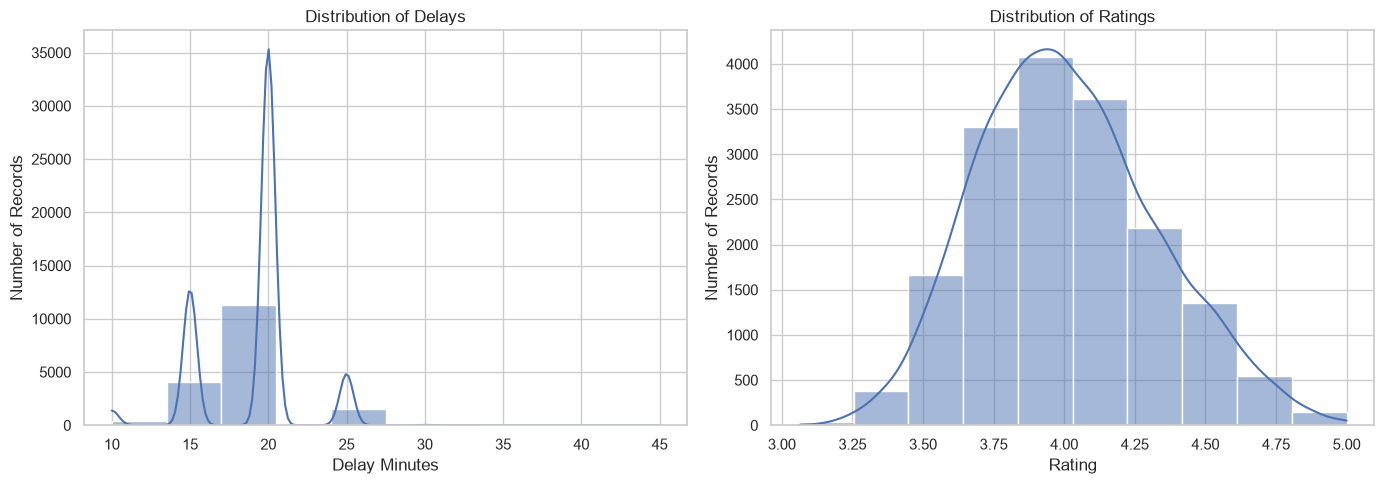

In [97]:
## Day 7 Tasks (Week 3)
## Distribution Analysis


import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    driver_profiles["delays_minutes"],
    bins=10,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Delays")
axes[0].set_xlabel("Delay Minutes")
axes[0].set_ylabel("Number of Records")

sns.histplot(
    driver_profiles["rating"],
    bins=10,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribution of Ratings")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("Number of Records")

plt.tight_layout()
plt.show()

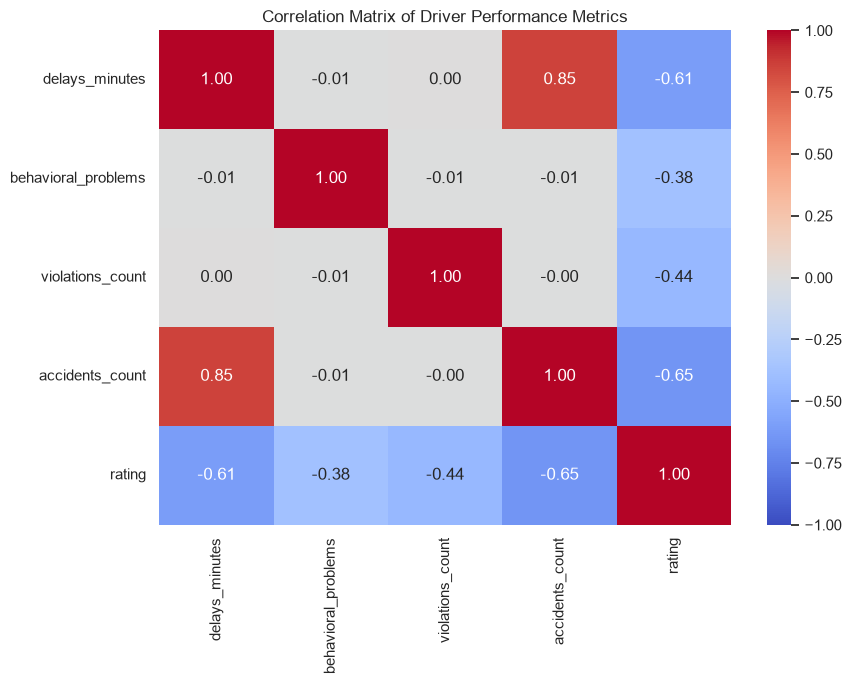

                     delays_minutes  behavioral_problems  violations_count  \
delays_minutes                 1.00                -0.01              0.00   
behavioral_problems           -0.01                 1.00             -0.01   
violations_count               0.00                -0.01              1.00   
accidents_count                0.85                -0.01             -0.00   
rating                        -0.61                -0.38             -0.44   

                     accidents_count  rating  
delays_minutes                  0.85   -0.61  
behavioral_problems            -0.01   -0.38  
violations_count               -0.00   -0.44  
accidents_count                 1.00   -0.65  
rating                         -0.65    1.00  


In [98]:
## Correlation Analysis
numeric_columns = [
    "delays_minutes",
    "behavioral_problems",
    "violations_count",
    "accidents_count",
    "rating",
]

correlation_matrix = driver_profiles[numeric_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Matrix of Driver Performance Metrics")
plt.tight_layout()
plt.show()

print(correlation_matrix.round(2))

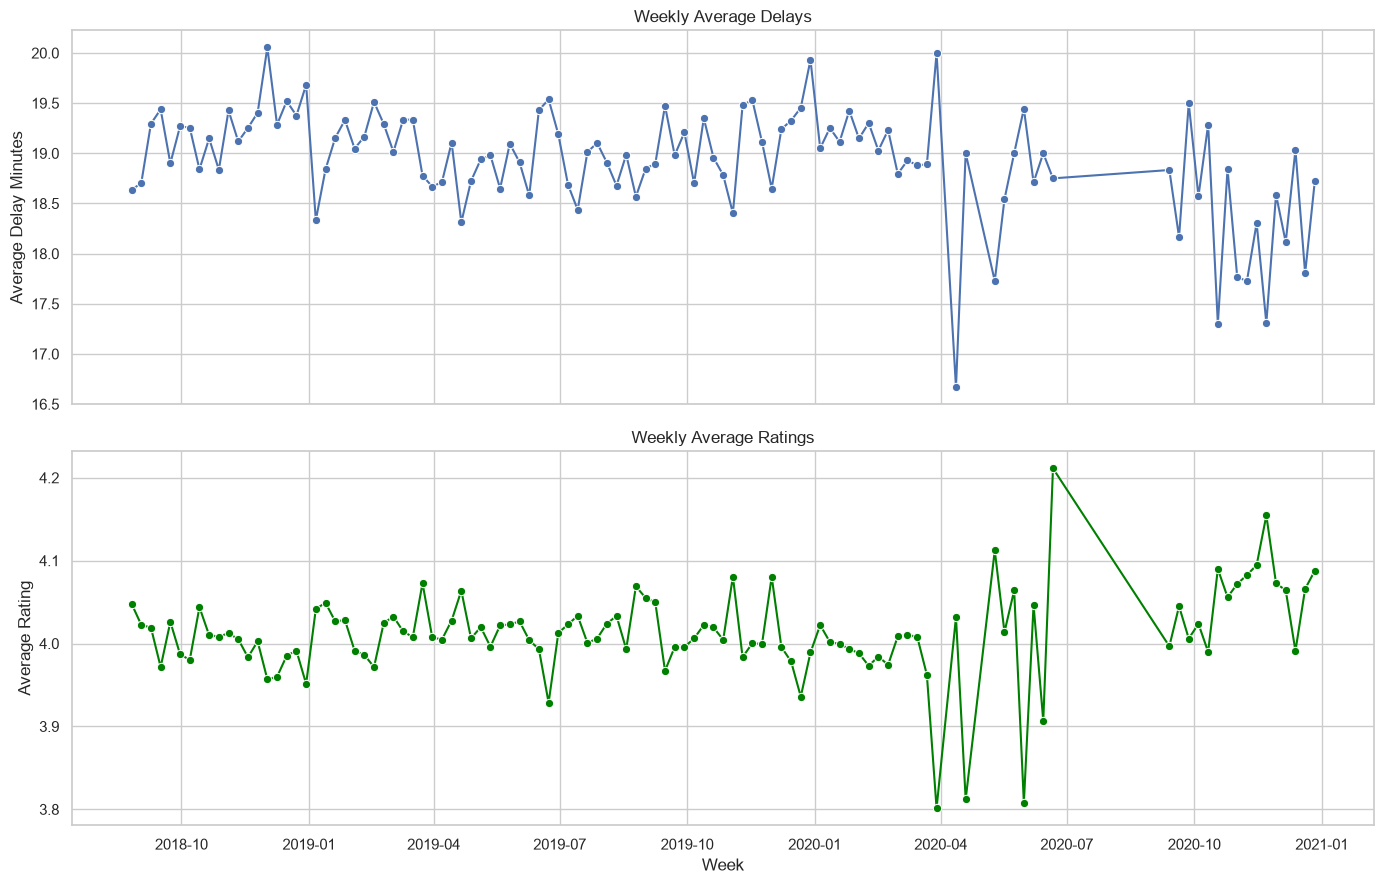

In [99]:
## Weekly Trends
weekly_metrics = (
    driver_profiles
    .set_index("date")
    .resample("W")
    .agg(
        average_delays=("delays_minutes", "mean"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

sns.lineplot(
    data=weekly_metrics,
    x="date",
    y="average_delays",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Weekly Average Delays")
axes[0].set_ylabel("Average Delay Minutes")
axes[0].set_xlabel("")

sns.lineplot(
    data=weekly_metrics,
    x="date",
    y="average_rating",
    marker="o",
    color="green",
    ax=axes[1]
)

axes[1].set_title("Weekly Average Ratings")
axes[1].set_ylabel("Average Rating")
axes[1].set_xlabel("Week")

plt.tight_layout()
plt.show()

delays_minutes:
  Lower limit: 7.50
  Upper limit: 27.50
  Outliers: 13

behavioral_problems:
  Lower limit: -3.00
  Upper limit: 5.00
  Outliers: 0

violations_count:
  Lower limit: -2.00
  Upper limit: 6.00
  Outliers: 0

accidents_count:
  Lower limit: -1.50
  Upper limit: 2.50
  Outliers: 0

rating:
  Lower limit: 3.12
  Upper limit: 4.88
  Outliers: 60



<Figure size 1400x800 with 0 Axes>

<Figure size 1400x800 with 0 Axes>

<Figure size 1400x800 with 0 Axes>

<Figure size 1400x800 with 0 Axes>

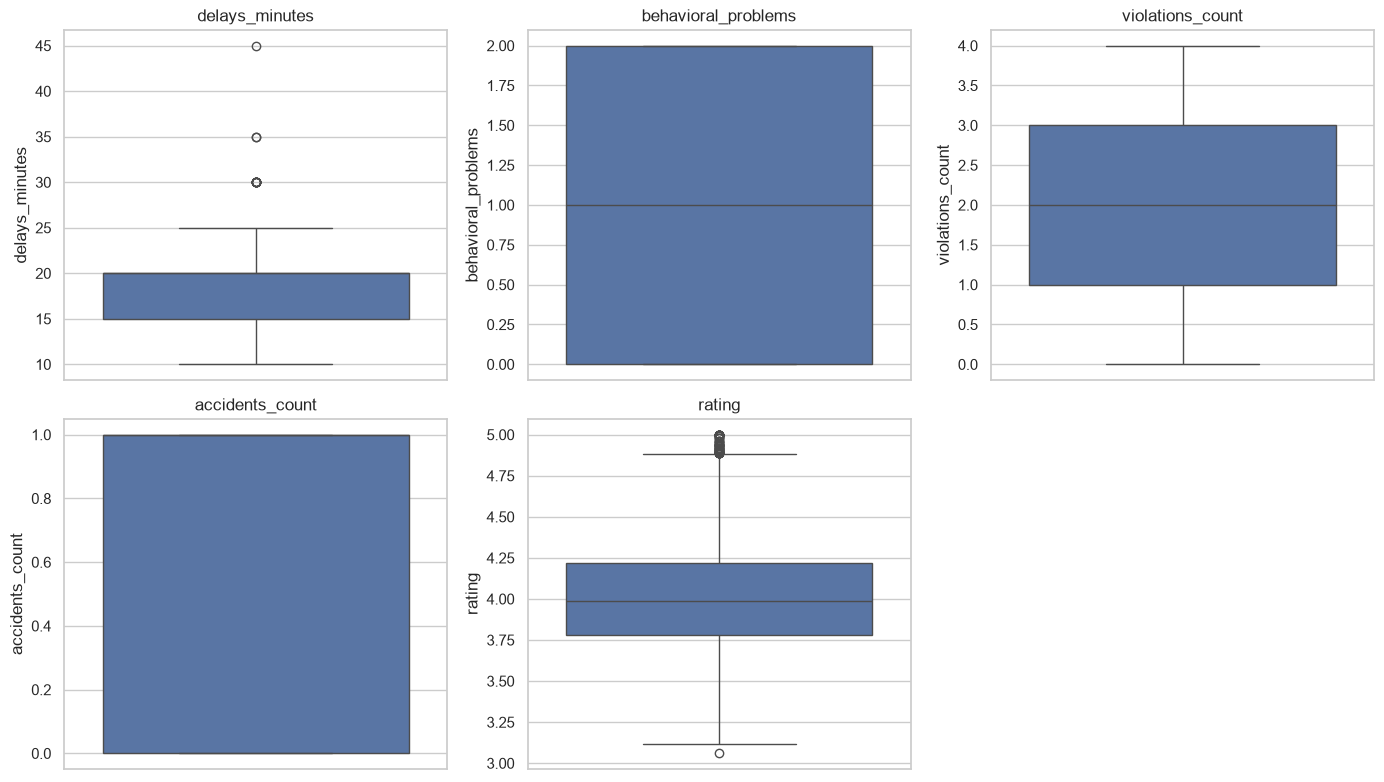

In [101]:
## Outlier Analysis
outlier_columns = [
    "delays_minutes",
    "behavioral_problems",
    "violations_count",
    "accidents_count",
    "rating",
]

outlier_summary = {}

for column in outlier_columns:
    q1 = driver_profiles[column].quantile(0.25)
    q3 = driver_profiles[column].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers = driver_profiles[
        (driver_profiles[column] < lower_limit)
        | (driver_profiles[column] > upper_limit)
    ]

    outlier_summary[column] = len(outliers)

    print(f"{column}:")
    print(f"  Lower limit: {lower_limit:.2f}")
    print(f"  Upper limit: {upper_limit:.2f}")
    print(f"  Outliers: {len(outliers)}")
    print()

    plt.figure(figsize=(14, 8))

for index, column in enumerate(outlier_columns, start=1):
    plt.subplot(2, 3, index)
    sns.boxplot(y=driver_profiles[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [102]:
print("Dataset summary")
print(f"Rows: {len(driver_profiles):,}")
print(f"Date range: {driver_profiles['date'].min().date()} to {driver_profiles['date'].max().date()}")
print(f"Average delays: {driver_profiles['delays_minutes'].mean():.2f} minutes")
print(f"Average rating: {driver_profiles['rating'].mean():.2f}")
print()

peak_delay_week = weekly_metrics.loc[
    weekly_metrics["average_delays"].idxmax()
]

lowest_rating_week = weekly_metrics.loc[
    weekly_metrics["average_rating"].idxmin()
]

print(
    "Peak delay week:",
    peak_delay_week["date"].date(),
    f"({peak_delay_week['average_delays']:.2f} minutes)"
)

print(
    "Lowest rating week:",
    lowest_rating_week["date"].date(),
    f"({lowest_rating_week['average_rating']:.2f})"
)

print()
print("Outlier counts:")
print(outlier_summary)

Dataset summary
Rows: 17,312
Date range: 2018-08-20 to 2020-12-27
Average delays: 19.03 minutes
Average rating: 4.01

Peak delay week: 2018-12-02 (20.05 minutes)
Lowest rating week: 2020-03-29 (3.80)

Outlier counts:
{'delays_minutes': 13, 'behavioral_problems': 0, 'violations_count': 0, 'accidents_count': 0, 'rating': 60}


## EDA Summary Observations

- The dataset contains 17,312 driver-performance records.
- The records cover the period from 2018-08-20 to 2020-12-27.
- The average delay was approximately 19.03 minutes.
- The average driver rating was approximately 4.01.
- The highest weekly average delay occurred during the week of 2018-12-02, at approximately 20.05 minutes.
- The lowest weekly average rating occurred during the week of 2020-03-29, at approximately 3.80.
- The correlation matrix was used to examine relationships among delays, behavioral problems, violations, accidents, and ratings.
- IQR analysis identified outliers in delays_minutes and rating.
- There were 13 delay outliers and 60 rating outliers.
- These outliers were retained because they may represent unusual but valid observations rather than data errors.
- Driver-specific metrics such as ratings, violations, and behavioral problems are synthetic educational variables derived from the MMDA traffic data. They should not be treated as actual individual-driver findings.